In [1]:
#0 Make pupil
#1 Generate 1 infinite phase screen
#2 Generate many many phase screens; say 10,000
   #based on previous phase screen object without redoing all necessary math within the 1st infinite screen
   #2.1 FLAT OUT PHASE SCREEN BEFORE STORING
#3 Make zernike modes
   #3.1 FLAT OUT BEFORE STORING
#4 Calculate orthonormal matrix
#5 Calculate cns of all phase screen
#6 Calculate variance of cns

#Measure std var method for only in the pupil

In [2]:
## imports ##

from aotools.turbulence import infinitephasescreen
from matplotlib import pyplot as plt
import numpy as np
from aotools import zernike
import pandas as pd
import random
%matplotlib inline

In [3]:
## inputs ##

#n:   0 1 2 3  4  5  6   7   8   9   10   11   12   13    14    15    16
#2^n: 1 2 4 8 16 32 64 128 256 512 1024 2048 4096 8192 16384 32768 65536

scrn_size=128
pixel_scale=0.1

r0=0.1
L0=20


#suggested zernike<scrn_size*pixel_scale/2r0
#radialDegree    1   2   3    4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
#zernike(approx) 1   3   6   10  15  21  28  36  45  55  66  78  91 105 120 136 153 171 190 210 231 253 276 300
radialDegree=10
Nzernike=int(radialDegree*(radialDegree+1)/2)

Nrandom=10000

In [4]:
## 0 Make pupil ##

x=np.arange(scrn_size)
x=x-scrn_size/2
xx,yy=np.meshgrid(x,x)
r=np.sqrt(xx**2+yy**2)
pupil=np.zeros(r.shape) # inside circle=1=True
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if r[i,j]<=scrn_size/2:
            pupil[i,j]=1
        else:
            pupil[i,j]=0
            
flat_pupil=pupil.flatten()

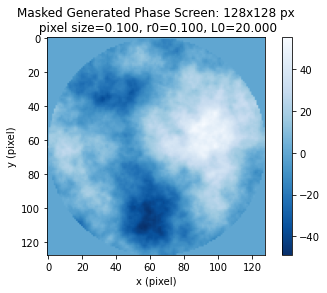

<Figure size 432x288 with 0 Axes>

In [5]:
## 1 Generate 1 infinite screen for structure function ##

phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)#number of pixel, pixel size, r0, L0
phase=phase_screen.scrn

color_map = plt.cm.get_cmap('Blues')
reversed_color_map = color_map.reversed()

plt.imshow(pupil*phase,cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: {:d}x{:d} px\n pixel size={:.3f}, r0={:.3f}, L0={:.3f}'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.colorbar()
plt.show()
plt.clf()

In [6]:
## 2 Generate many many more screens (10,000) --> flatten --> then store ##
phases=[]
for i in np.arange(Nrandom):
    phase_screen.make_initial_screen()
    phase=phase_screen.scrn
    phases.append(phase.flatten())

In [7]:
## 3 Make Zernike modes --> flatten --> store ##
flat_modes=[]
modes=zernike.zernikeArray(Nzernike,scrn_size)
for i in np.arange(Nzernike):
    flat_modes.append(modes[i].flatten())

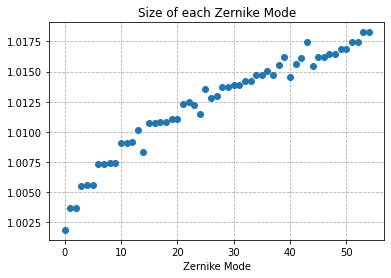

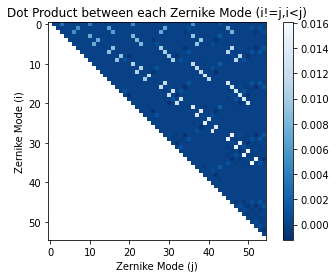

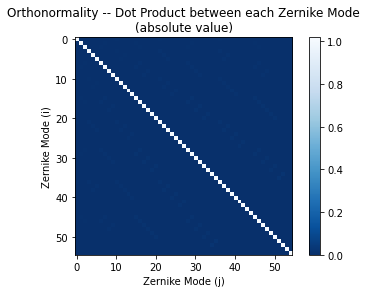

<Figure size 432x288 with 0 Axes>

In [8]:
## 4 Calculate orthonormal matrix ##
# if using new method for coefficient calculation

# Make orthonormal matrix
orthonormality=np.zeros((Nzernike,Nzernike))

area=np.pi*(scrn_size/2)**2

# Normality
normality_check=np.zeros(Nzernike)
for i in np.arange(Nzernike):
    normality_check[i]=np.dot(flat_modes[i],flat_modes[i])/area
    orthonormality[i,i]=normality_check[i]

plt.plot(normality_check,ls='',marker='o')
plt.xlabel('Zernike Mode')
#plt.ylim((0,max(normality_check)))
plt.title('Size of each Zernike Mode')
plt.grid(True,which="both", linestyle='--')
plt.savefig('normality')
plt.show()
plt.clf()

# Orthogonality
orthogonality_check=np.empty((Nzernike,Nzernike))
orthogonality_check[:,:]=np.NaN
for i in np.arange(Nzernike):
    for j in np.arange(Nzernike):
        if i!=j:
            if i<j:
                orthogonality_check[i,j]=np.dot(flat_modes[i],flat_modes[j])/area
                orthonormality[i,j]=orthogonality_check[i,j]
                orthonormality[j,i]=orthogonality_check[i,j]
        
plt.imshow(orthogonality_check,cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('Dot Product between each Zernike Mode (i!=j,i<j)')
plt.colorbar()
plt.savefig('orthogonality')
plt.show()
plt.clf()

plt.imshow(np.abs(orthonormality),cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('Orthonormality -- Dot Product between each Zernike Mode\n(absolute value)')
plt.colorbar()
plt.savefig('orthonormality')
plt.show()
plt.clf()

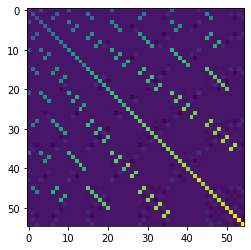

In [21]:
## 5 Calculate Cns of each screen --> store ##


# regular method --> cns=phase dot modes
#coeffs=np.zeros((Nrandom,Nzernike)) #coeffs[sample,mode]
#for i in np.arange(Nrandom):
#    for j in range(Nzernike):
#        coeffs[i,j]=np.dot(flat_pupil*phases[i],flat_modes[j])/area


# new method --> (phase dot modes) = orthonormal matrix matrix multiply cns
#            --> cns = (phase dot modes) matrix multiply inverse orthonormal matrix

inverse_orthonormality=np.linalg.inv(orthonormality)
coeffs=[]
phase_dot_modes=np.zeros(Nzernike)
for i in np.arange(Nrandom):
    for j in np.arange(Nzernike):
        phase_dot_modes[j]=np.dot(flat_pupil*phases[i],flat_modes[j])/area
    coeffs.append(np.matmul(inverse_orthonormality,phase_dot_modes))
coeffs=np.array(coeffs)

plt.imshow(orthonormality-inverse_orthonormality)

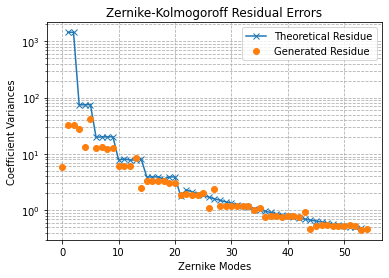

<Figure size 432x288 with 0 Axes>

In [22]:
## 6 Calculate mean & variance of each cns ##

#coeffs shape = (Nrandom,Nzernike)
variance_cns=np.zeros(Nzernike)
#mean_cns=np.zeros(Nzernike)

for i in np.arange(Nzernike): # for each zernike mode
#    mean_cns[i]=np.mean(coeffs[:,i]) # through all samples
    variance_cns[i]=np.var(coeffs[:,i])
    
#plt.plot(np.abs(mean_cns),marker='o',ls='')
#plt.title('Absolute Coefficients Mean of each Zernike Modes')
#plt.xlabel('Zernike Modes')
#plt.ylabel('Abosolute Coefficient Mean')
#plt.yscale('log')
#plt.grid(True,which="both", linestyle='--')
#plt.show()
#plt.clf()

temp=np.array([1.0299,0.582,0.134,0.111,0.0880,
      0.0648,0.0587,0.0525,0.0463,0.0401,
      0.0377,0.0352,0.0328,0.0304,0.0279,
      0.0267,0.0255,0.0243,0.0232,0.0220,0.0208])

res=[]
for i in range(len(temp)-1):
    res.append(temp[i]-temp[i+1])
    
if Nzernike>=20:
    temp2=np.arange(22,Nzernike+1)
    res.append(temp[-1]-0.2944*temp2[0]**(-np.sqrt(3)/2.))
    for i in range(len(temp2)-2):
        res.append(0.2944*((temp2[i+1])**(-np.sqrt(3)/2.)-(temp2[i+2])**(-np.sqrt(3)/2.)))
    plt.plot(np.arange(Nzernike-2)+1,np.array(res)*(scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue',marker='x')
else:
    plt.plot(np.arange(0,Nzernike)+1,np.array(res)[0:Nzernike]*(scrn_size*pixel_scale/r0)**(5./3.),label='Theoretical Residue')

plt.plot(variance_cns,marker='o',ls='',label='Generated Residue')
plt.title('Zernike-Kolmogoroff Residual Errors')
plt.xlabel('Zernike Modes')
plt.ylabel('Coefficient Variances')
plt.yscale('log')
plt.grid(True,which="both", linestyle='--')
plt.legend()
#plt.xlim(20,50)
#plt.ylim(0.5,5)
#plt.xlim(0,20)
#plt.ylim(0,20)
plt.savefig('ResidualErrors')
plt.show()
plt.clf()

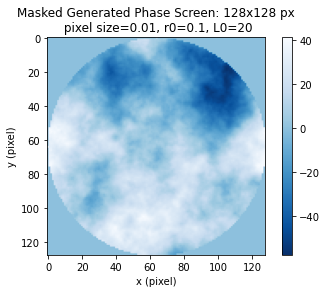

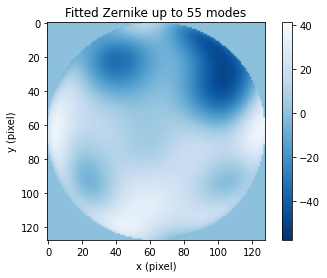

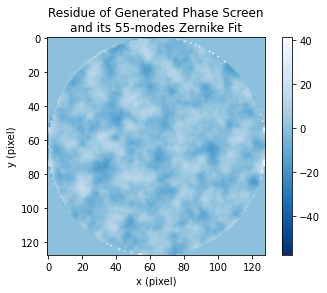

observe rms=
20.229069896969804
fit rms=
19.422869994658775
residue rms=
5.402390596258668


<Figure size 432x288 with 0 Axes>

In [23]:
test_scrn=10

observe=pupil*phases[test_scrn].reshape((scrn_size,scrn_size))
calculate=zernike.phaseFromZernikes(coeffs[test_scrn],scrn_size)
residue=observe-calculate

mapmax=observe.max()
mapmin=observe.min()

plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: 128x128 px\n pixel size=0.01, r0=0.1, L0=20')
plt.colorbar()
plt.savefig('PhaseScreen')
plt.show()
plt.clf()

plt.imshow(calculate,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Fitted Zernike up to {:d} modes'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('FittedZernike')
plt.show()
plt.clf()


plt.imshow(residue,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Residue of Generated Phase Screen\nand its {:d}-modes Zernike Fit'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('Residue')
plt.show()
plt.clf()

obs_rms=0.
calc_rms=0.
res_rms=0.

obs_n=pupil.sum()
calc_n=pupil.sum()
res_n=pupil.sum()

obs_mean=(pupil*observe).sum()/obs_n
calc_mean=(pupil*calculate).sum()/calc_n
res_mean=(pupil*residue).sum()/res_n

for i in np.arange(scrn_size):
    for j in np.arange(scrn_size):
        if pupil[i,j]==1:
            obs_rms=obs_rms+(observe[i,j]-obs_mean)**2
            calc_rms=calc_rms+(calculate[i,j]-calc_mean)**2
            res_rms=res_rms+(residue[i,j]-res_mean)**2
            
obs_rms=np.sqrt(obs_rms/(obs_n-1))
calc_rms=np.sqrt(calc_rms/(calc_n-1))
res_rms=np.sqrt(res_rms/(res_n-1))

print('observe rms=')
print(obs_rms)
print('fit rms=')
print(calc_rms)
print('residue rms=')
print(res_rms)